<a href="https://colab.research.google.com/github/Dhenielc15/SY.26-27_CCADMACL_DEMO/blob/main/Demo_1_Generative%26Discriminative.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DEMO — Generative vs Discriminative Models

In this demo we walk through the **same steps as Exercise 1**, but with a different dataset: **Breast Cancer Wisconsin**.

**Goal:** Predict if a breast tumor is **benign** (not cancer) or **malignant** (cancer) using measurements of its cells taken from a scan.

This is a **supervised learning** problem: we have features (`Radius`, `Texture`, `Smoothness`, `ConcavePoints`, `Symmetry`) and a label (`Diagnosis`). We will train two kinds of classifiers and **visualize** how each one thinks:

- **Part 1 — Generative (Naive Bayes):** learns the **joint probability** of the features and the label. It learns the *shape* of each group (benign / malignant).
- **Part 2 — Discriminative (Logistic Regression):** learns the **conditional probability** of the label given the features **directly**. It learns a *boundary* that separates the groups.

Dataset: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

---

## Objectives

By the end of this demo, you should be able to:

1. Explain the difference between a **generative** model (learns the joint probability) and a **discriminative** model (learns the conditional probability directly).
2. Follow the steps to train a **Naive Bayes** model (generative) and a **Logistic Regression** model (discriminative) using scikit-learn.
3. Make predictions on test data and measure **accuracy**.
4. Read the **visualizations** of each model: the *shape of each group* for the generative model, and the *decision boundary* for the discriminative model.
5. Apply the same steps to a new dataset in **Exercise 1**.

## Expected Outcomes

After running every cell, you should see:

| Section | Expected outcome |
|---|---|
| 3 & 6 | Two trained models: `nb` (Naive Bayes) and `logreg` (Logistic Regression) |
| 4 & 7 | Test accuracy for each model: about **0.90** for Naive Bayes and about **0.92** for Logistic Regression |
| 5 | A plot with **two filled shapes**: a small blue one at the bottom left (benign tumors) and a bigger red one at the top right (malignant tumors) |
| 8 | A plot with the same dots and **one gray line** (the decision boundary) between benign and malignant |
| 9 | A comparison table and bar chart of both models |

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

In [2]:
# Downloads the dataset from Kaggle automatically (no API key needed)
datasetpath = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
dataseturl = glob.glob(os.path.join(datasetpath, "**", "*.csv"), recursive=True)[0]

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


## 1. Load the Dataset

We read the CSV file into a pandas DataFrame called `df` and look at the first 5 rows.

Each row is one tumor. The `diagnosis` column is what we want to predict: `B` = benign, `M` = malignant.

In [3]:
df = pd.read_csv(dataseturl)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 2. Prepare the Data

The dataset has 30 measurements. We keep only 5 of them and give them short names:

| Column | Meaning | Encoding |
|---|---|---|
| `Radius` | average size of the cells *(feature)* | number |
| `Texture` | how uneven the cell colors are *(feature)* | number |
| `Smoothness` | how smooth the cell edges are *(feature)* | percent (× 100) |
| `ConcavePoints` | how many dents the cell edges have *(feature)* | percent (× 100) |
| `Symmetry` | how symmetric the cells are *(feature)* | percent (× 100) |
| `Diagnosis` | is the tumor cancer? *(label)* | 0 = benign, 1 = malignant |

`Smoothness`, `ConcavePoints` and `Symmetry` are very small numbers (like 0.05), so we multiply them by 100 to put all features on a similar scale. This helps Logistic Regression learn.

Then we split the data:

- **80% training** → `X_train`, `y_train` (the model learns from these)
- **20% testing** → `X_test`, `y_test` (we check the model on tumors it has never seen)

We also prepare things for the visualizations:

- `grid`, `xx`, `yy` — a grid of `Radius` / `ConcavePoints` points that covers the whole plot. We ask the model about every point to draw shapes and boundaries.
- `colors` and `labels` — the color and legend name of each group: `0` = Benign (blue), `1` = Malignant (red).

In [4]:
data = pd.DataFrame({
    "Radius":        df["radius_mean"],
    "Texture":       df["texture_mean"],
    "Smoothness":    df["smoothness_mean"] * 100,
    "ConcavePoints": df["concave points_mean"] * 100,
    "Symmetry":      df["symmetry_mean"] * 100,
    "Diagnosis":     (df["diagnosis"] == "M").astype(int),     # 0 = benign, 1 = malignant
})

features = ["Radius", "Texture", "Smoothness", "ConcavePoints", "Symmetry"]

train, test = train_test_split(data, test_size=0.2, stratify=data["Diagnosis"], random_state=42)

X_train, y_train = train[features], train["Diagnosis"]
X_test,  y_test  = test[features],  test["Diagnosis"]

# ---- For the visualizations ----
# Grid of (Radius, ConcavePoints) points that covers the whole plot
xx, yy = np.meshgrid(np.linspace(5, 30, 300), np.linspace(-3, 22, 300))
grid = pd.DataFrame({"Radius": xx.ravel(), "ConcavePoints": yy.ravel()})

colors = {0: "#1f8bb5", 1: "#d1495b"}
labels = {0: "Benign", 1: "Malignant"}

print("Train:", X_train.shape, " Test:", X_test.shape)
X_train.head()

Train: (455, 5)  Test: (114, 5)


,Radius,Texture,Smoothness,ConcavePoints,Symmetry
10,16.02,23.24,8.206,3.323,15.28
170,12.32,12.39,10.280,3.700,19.59
407,12.85,21.37,7.551,1.867,15.80
430,14.90,22.53,9.947,9.711,20.41
27,18.61,20.25,9.440,7.731,16.97


# PART 1 — GENERATIVE: Naive Bayes

A generative model learns **how each group's data is spread out**: what benign tumors usually look like, and what malignant tumors usually look like.
From this it gets the **joint probability** of the features and the label, then uses **Bayes' rule** to classify a new tumor.

We use `GaussianNB`, a Naive Bayes model for numeric features.

## 3. Train the Model

**Step 1:** Create the model with `GaussianNB()` and call it `nb`.

**Step 2:** Train it with `nb.fit(X_train, y_train)`. During training, Naive Bayes looks at each group separately and learns the average and spread of every feature in that group.

In [5]:
# Generative model: learns how the features are spread out inside each group
nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

## 4. Predict and Evaluate

**Step 1:** Use `nb.predict(X_test)` to predict the label of every test tumor. We save the predictions as `pred_nb`.

**Step 2:** Compare the predictions with the real answers `y_test` using `accuracy_score`. Accuracy = the share of tumors the model got right.

In [6]:
pred_nb = nb.predict(X_test)

acc_nb = accuracy_score(y_test, pred_nb)
print("Naive Bayes test accuracy:", round(acc_nb, 4))

Naive Bayes test accuracy: 0.9035


## 5. Visualize the Generative Model

Now we draw the **shape of each group** that Naive Bayes learned.

A plot only has 2 axes, but `nb` uses 5 features. So for the plot, we train a small copy of the model that uses only **2 features**: `Radius` (x-axis) and `ConcavePoints` (y-axis).

**Step 1:** Train `nb_2d = GaussianNB()` on `X_train[["Radius", "ConcavePoints"]]`.

**Step 2:** Compute the **joint probability** of every point in `grid` with `nb_2d.predict_joint_log_proba(grid)`. It returns the *log* of the probability, so we use `np.exp(...)` to undo the log. Column `0` = Benign, column `1` = Malignant.

**Step 3:** For each group, draw a **filled shape** with `plt.contourf` where its joint probability is high, and an **outline** around it with `plt.contour`.

**Step 4:** Draw the tumors as dots with `plt.scatter`, using `colors` and `labels`.

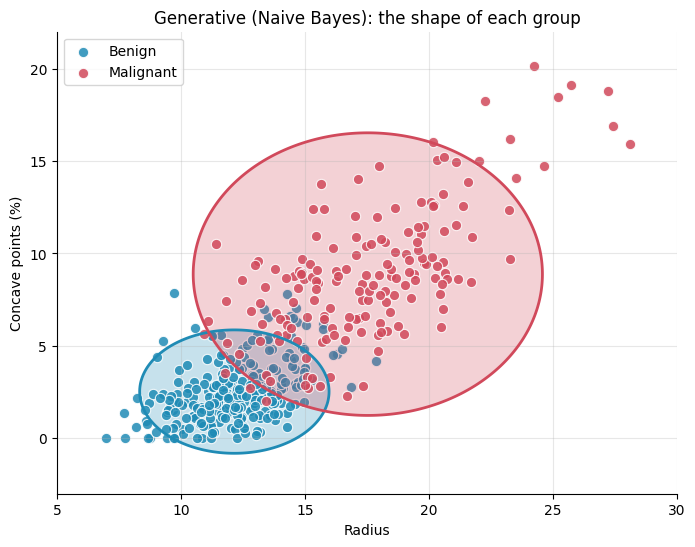

In [7]:
# 1. Small copy of the model with only Radius and ConcavePoints, so we can draw it
nb_2d = GaussianNB()
nb_2d.fit(X_train[["Radius", "ConcavePoints"]], y_train)

# 2. Joint probability of every grid point, for each group
joint_nb = np.exp(nb_2d.predict_joint_log_proba(grid))

fig, ax = plt.subplots(figsize=(8, 6))
for k in [0, 1]:
    # 3. Filled shape + outline = where the model thinks group k is
    z = joint_nb[:, k].reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[z.max() * 0.1, z.max()], colors=colors[k], alpha=0.25)
    ax.contour(xx, yy, z, levels=[z.max() * 0.1], colors=colors[k], linewidths=2)

    # 4. The tumors of group k
    ax.scatter(X_train.loc[y_train == k, "Radius"], X_train.loc[y_train == k, "ConcavePoints"],
               c=colors[k], edgecolors="white", linewidths=0.8, s=55, alpha=0.85, label=labels[k])

ax.set_xlabel("Radius")
ax.set_ylabel("Concave points (%)")
ax.set_title("Generative (Naive Bayes): the shape of each group")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.show()

### What the plot shows

- **Each dot is one tumor** from the training data. Blue = benign, red = malignant. Its position shows the tumor's `Radius` (left to right) and `ConcavePoints` (bottom to top).
- **Each shaded shape is one group, as the model learned it.** The shape covers the area where the model expects most tumors of that group to be. It comes from the **joint probability**: how likely it is to see a tumor *of that group* *with those measurements*.
- **The blue shape (benign) is small and sits at the bottom left.** Benign tumors usually have small cells with few dents, and they are all quite similar to each other, so the shape is tight.
- **The red shape (malignant) is bigger and sits at the top right.** Malignant tumors usually have bigger cells with more dents, and they vary a lot from tumor to tumor, so the shape is wide.
- **The shapes overlap a little in the middle.** A few tumors there could belong to either group. These are the tumors the model is most likely to get wrong.

**Key idea:** a generative model learns **what each group looks like on its own**. To classify a new tumor, it checks which group's shape fits the tumor better.

# PART 2 — DISCRIMINATIVE: Logistic Regression

A discriminative model does **not** learn how each group's data is spread out.
It learns the **conditional probability** of malignant given the features **directly**, and draws a **decision boundary** between the groups.

We use `LogisticRegression`.

## 6. Train the Model

**Step 1:** Create the model with `LogisticRegression(max_iter=1000)` and call it `logreg`. (`max_iter=1000` gives the model enough steps to finish learning.)

**Step 2:** Train it with `logreg.fit(X_train, y_train)`. During training, Logistic Regression looks for the best line (boundary) that separates the two groups.

In [8]:
# Discriminative model: learns the conditional probability directly
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

## 7. Predict and Evaluate

Same steps as Section 4, but with `logreg`:

**Step 1:** Predict the test tumors with `logreg.predict(X_test)` and save them as `pred_lr`.

**Step 2:** Compute the accuracy with `accuracy_score` and save it as `acc_lr`.

In [9]:
pred_lr = logreg.predict(X_test)

acc_lr = accuracy_score(y_test, pred_lr)
print("Logistic Regression test accuracy:", round(acc_lr, 4))

Logistic Regression test accuracy: 0.9211


## 8. Visualize the Discriminative Model

Now we draw the **decision boundary** that Logistic Regression learned. Just like Section 5, we train a small copy of the model on only `Radius` and `ConcavePoints`.

**Step 1:** Train `logreg_2d = LogisticRegression(max_iter=1000)` on `X_train[["Radius", "ConcavePoints"]]`.

**Step 2:** Compute the **conditional probability** of malignant for every point in `grid` with `logreg_2d.predict_proba(grid)[:, 1]`. We save it as `cond_lr`.

**Step 3:** Draw the tumors as dots (same as Section 5, but without the shapes).

**Step 4:** Draw the **decision boundary** with `plt.contour(..., levels=[0.5])`: the line where the model is 50/50.

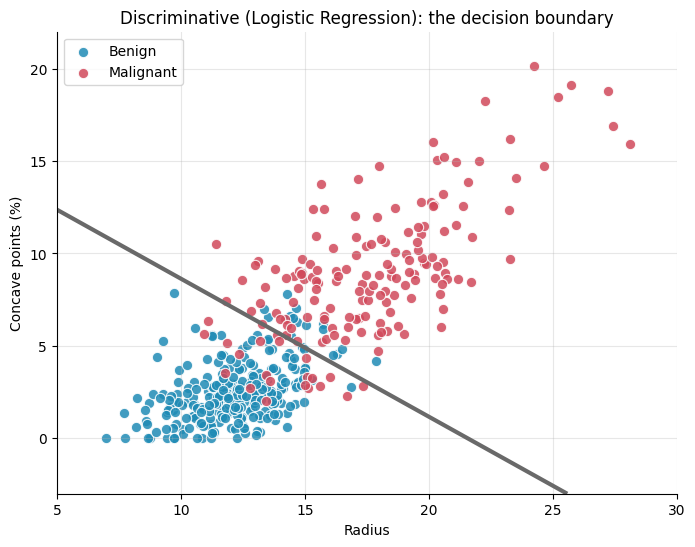

In [10]:
# 1. Small copy of the model with only Radius and ConcavePoints, so we can draw it
logreg_2d = LogisticRegression(max_iter=1000)
logreg_2d.fit(X_train[["Radius", "ConcavePoints"]], y_train)

# 2. Conditional probability of malignant for every grid point
cond_lr = logreg_2d.predict_proba(grid)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))

# 3. The tumors of each group
for k in [0, 1]:
    ax.scatter(X_train.loc[y_train == k, "Radius"], X_train.loc[y_train == k, "ConcavePoints"],
               c=colors[k], edgecolors="white", linewidths=0.8, s=55, alpha=0.85, label=labels[k])

# 4. Decision boundary = where the model is 50/50
ax.contour(xx, yy, cond_lr.reshape(xx.shape), levels=[0.5], colors="dimgray", linewidths=3)

ax.set_xlabel("Radius")
ax.set_ylabel("Concave points (%)")
ax.set_title("Discriminative (Logistic Regression): the decision boundary")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.show()

### What the plot shows

- **The dots are the same tumors** as in Section 5. Blue = benign, red = malignant.
- **There are no shapes this time, only one gray line: the decision boundary.** On this line, the model's **conditional probability** of malignant is exactly 0.5 (50/50).
- **Below / left of the line, the model predicts benign.** Small cells with few dents.
- **Above / right of the line, the model predicts malignant.** Bigger cells with more dents.
- **The farther a tumor is from the line, the more sure the model is.** Tumors close to the line are the hard cases. The few dots on the "wrong" side of the line are the tumors the model gets wrong.
- **The line is straight.** Logistic Regression always draws a straight line (with 2 features) between the groups.

**Key idea:** a discriminative model does **not** learn what each group looks like. It only learns **where to draw the line** that separates them.

**Compare with Section 5:** the generative model drew a *shape for each group*; the discriminative model drew *one line between the groups*. Both answer the same question (benign or malignant?) in different ways.

## 9. Compare the Models

Finally, we put both models side by side: which type each one is, which probability it learns, and its test accuracy.

,Model,Type,Learns,Test Accuracy
0,Naive Bayes (GaussianNB),Generative,Joint probability,0.9035
1,Logistic Regression,Discriminative,Conditional probability,0.9211


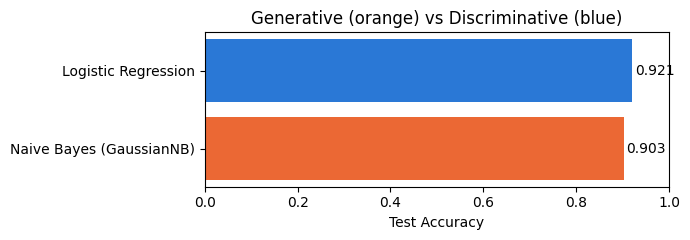

In [11]:
# Compares the generative model (Part 1) and the discriminative model (Part 2)
comparison = pd.DataFrame({
    "Model": ["Naive Bayes (GaussianNB)", "Logistic Regression"],
    "Type":  ["Generative", "Discriminative"],
    "Learns": ["Joint probability", "Conditional probability"],
    "Test Accuracy": [acc_nb, acc_lr],
}).round(4)
display(comparison)

bar_colors = comparison["Type"].map({"Generative": "#eb6834", "Discriminative": "#2a78d6"})
plt.figure(figsize=(7, 2.5))
plt.barh(comparison["Model"], comparison["Test Accuracy"], color=bar_colors)
for i, v in enumerate(comparison["Test Accuracy"]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.xlim(0, 1)
plt.xlabel("Test Accuracy")
plt.title("Generative (orange) vs Discriminative (blue)")
plt.tight_layout()
plt.show()